<a href="https://colab.research.google.com/github/giriprasath-12/Traffic-Prediction/blob/main/Trafficpredict.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install pandas numpy matplotlib scikit-learn tensorflow

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("TrafficVolumeData.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Saving TrafficVolumeData.csv to TrafficVolumeData.csv
Dataset loaded successfully!
Dataset shape: (33750, 15)


,date_time,is_holiday,air_pollution_index,humidity,wind_speed,wind_direction,visibility_in_miles,dew_point,temperature,rain_p_h,snow_p_h,clouds_all,weather_type,weather_description,traffic_volume
0,2012-10-02 09:00:00,NaN,121,89,2,329,1,1,288.28,0.0,0.0,40,Clouds,scattered clouds,5545
1,2012-10-02 10:00:00,NaN,178,67,3,330,1,1,289.36,0.0,0.0,75,Clouds,broken clouds,4516
2,2012-10-02 11:00:00,NaN,113,66,3,329,2,2,289.58,0.0,0.0,90,Clouds,overcast clouds,4767
3,2012-10-02 12:00:00,NaN,20,66,3,329,5,5,290.13,0.0,0.0,90,Clouds,overcast clouds,5026
4,2012-10-02 13:00:00,NaN,281,65,3,329,7,7,291.14,0.0,0.0,75,Clouds,broken clouds,4918


In [7]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Column names:
['date_time', 'is_holiday', 'air_pollution_index', 'humidity', 'wind_speed', 'wind_direction', 'visibility_in_miles', 'dew_point', 'temperature', 'rain_p_h', 'snow_p_h', 'clouds_all', 'weather_type', 'weather_description', 'traffic_volume']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33750 entries, 0 to 33749
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date_time            33750 non-null  object 
 1   is_holiday           43 non-null     object 
 2   air_pollution_index  33750 non-null  int64  
 3   humidity             33750 non-null  int64  
 4   wind_speed           33750 non-null  int64  
 5   wind_direction       33750 non-null  int64  
 6   visibility_in_miles  33750 non-null  int64  
 7   dew_point            33750 non-null  int64  
 8   temperature          33750 non-null  float64
 9   rain_p_h             33750 non-null  float64
 10  snow_p_h 

,air_pollution_index,humidity,wind_speed,wind_direction,visibility_in_miles,dew_point,temperature,rain_p_h,snow_p_h,clouds_all,traffic_volume
count,33750.000000,33750.000000,33750.000000,33750.000000,33750.000000,33750.000000,33750.000000,33750.000000,33750.000000,33750.000000,33750.000000
mean,154.841422,71.209007,3.378193,199.471852,4.989748,4.989748,280.069587,0.448739,0.000318,50.458785,3240.118163
std,83.735515,16.852248,2.055792,99.841088,2.570021,2.570021,13.415256,53.526500,0.009760,38.871734,1991.487289
min,10.000000,13.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,83.000000,60.000000,2.000000,130.000000,3.000000,3.000000,271.720000,0.000000,0.000000,1.000000,1165.250000
50%,155.000000,72.000000,3.000000,200.000000,5.000000,5.000000,280.150000,0.000000,0.000000,64.000000,3335.000000
75%,228.000000,85.000000,5.000000,290.000000,7.000000,7.000000,290.620000,0.000000,0.000000,90.000000,4926.000000
max,299.000000,100.000000,16.000000,360.000000,9.000000,9.000000,308.240000,9831.300000,0.510000,100.000000,7280.000000


In [8]:
df["date_time"] = pd.to_datetime(df["date_time"])

df = df.sort_values("date_time").reset_index(drop=True)

print("First record:", df["date_time"].min())
print("Last record:", df["date_time"].max())
print("Total records:", len(df))

First record: 2012-10-02 09:00:00
Last record: 2017-05-17 23:00:00
Total records: 33750


In [9]:
# Check for missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows with missing date or target
df = df.dropna(subset=["date_time", "traffic_volume"])

# Sort by date and time
df = df.sort_values("date_time")

# Check duplicate timestamps
print("Duplicate timestamps:", df["date_time"].duplicated().sum())

# Keep the dataset ready for processing
df = df.reset_index(drop=True)

print("Shape after cleaning:", df.shape)

Missing values before cleaning:
date_time                  0
is_holiday             33707
air_pollution_index        0
humidity                   0
wind_speed                 0
wind_direction             0
visibility_in_miles        0
dew_point                  0
temperature                0
rain_p_h                   0
snow_p_h                   0
clouds_all                 0
weather_type               0
weather_description        0
traffic_volume             0
dtype: int64
Duplicate timestamps: 5161
Shape after cleaning: (33750, 15)


Total hourly slots: 40527
Missing hourly slots: 11938


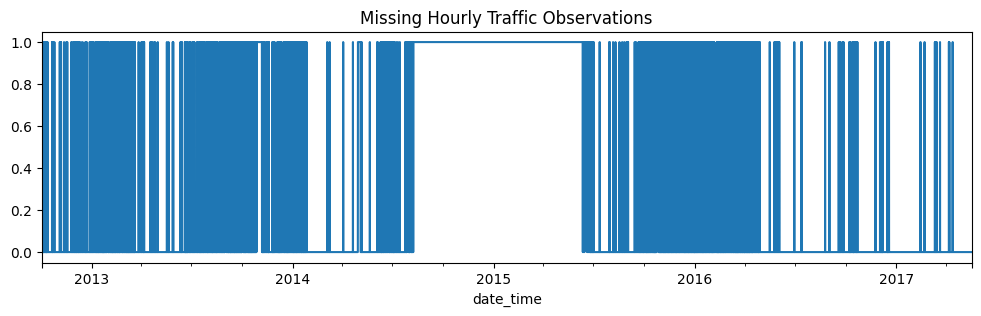

In [10]:
# Create one traffic value per hour
hourly = (
    df.set_index("date_time")["traffic_volume"]
      .resample("h")
      .mean()
      .sort_index()
)

print("Total hourly slots:", len(hourly))
print("Missing hourly slots:", hourly.isna().sum())

# Visualize missing hours
hourly.isna().astype(int).plot(
    figsize=(12, 3),
    title="Missing Hourly Traffic Observations"
)
plt.show()

In [13]:
import pandas as pd
import numpy as np
from google.colab import files
import os

# Load the dataset if it is not already in memory
if "df" not in globals():
    if os.path.exists("TrafficVolumeData.csv"):
        df = pd.read_csv("TrafficVolumeData.csv")
    else:
        uploaded = files.upload()
        filename = next(iter(uploaded))
        df = pd.read_csv(filename)

# Prepare data
df.columns = df.columns.str.strip()
df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")
df["traffic_volume"] = pd.to_numeric(
    df["traffic_volume"], errors="coerce"
)
df = df.dropna(subset=["date_time", "traffic_volume"])

# One traffic value per timestamp
hourly = df.groupby("date_time")["traffic_volume"].mean().sort_index()

# Find continuous hourly segments
segments = []
current = []

for timestamp, value in hourly.items():
    if current and timestamp - current[-1][0] != pd.Timedelta(hours=1):
        segments.append(current)
        current = []
    current.append((timestamp, value))

if current:
    segments.append(current)

longest = max(segments, key=len)

print("Longest consecutive hourly segment:", len(longest))

if len(longest) >= 2000:
    traffic = np.array([v for t, v in longest[:2000]]).reshape(-1, 1)
    print("Traffic variable created:", traffic.shape)
else:
    print("This dataset does not contain 2000 consecutive hourly records.")

Longest consecutive hourly segment: 1365
This dataset does not contain 2000 consecutive hourly records.


Dataset loaded successfully!
Longest consecutive segment: 1365
Traffic variable shape: (1365, 1)


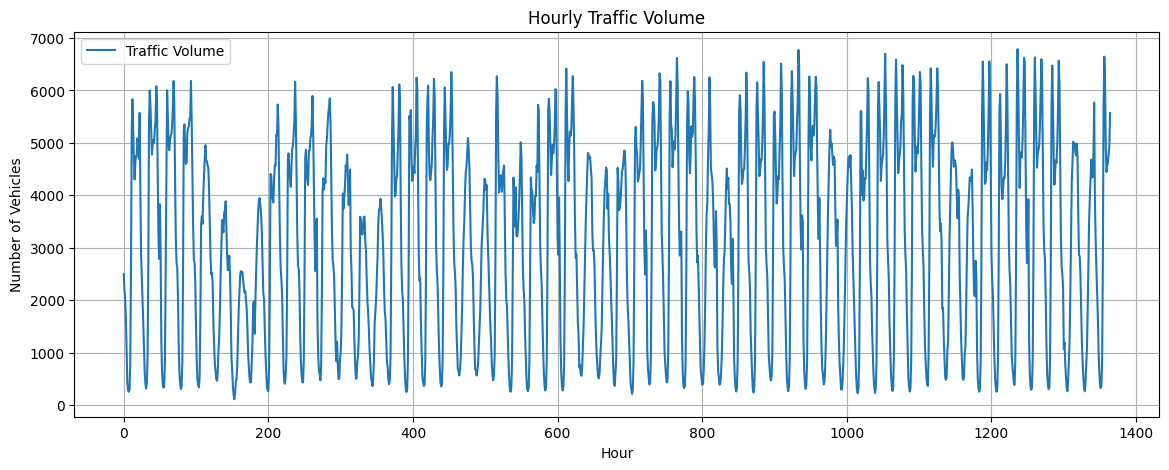

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import os

# 1. Load dataset
if os.path.exists("TrafficVolumeData.csv"):
    df = pd.read_csv("TrafficVolumeData.csv")
else:
    uploaded = files.upload()
    filename = next(iter(uploaded))
    df = pd.read_csv(filename)

# 2. Clean data
df.columns = df.columns.str.strip()
df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")
df["traffic_volume"] = pd.to_numeric(
    df["traffic_volume"], errors="coerce"
)
df = df.dropna(subset=["date_time", "traffic_volume"])

# 3. Combine duplicate timestamps
hourly = (
    df.groupby("date_time")["traffic_volume"]
      .mean()
      .sort_index()
)

# 4. Find the longest consecutive hourly segment
segments = []
current = []

for timestamp, value in hourly.items():
    if current and timestamp - current[-1][0] != pd.Timedelta(hours=1):
        segments.append(current)
        current = []
    current.append((timestamp, value))

if current:
    segments.append(current)

longest = max(segments, key=len)

# Create traffic variable, even if fewer than 2000 records
traffic = np.array([value for timestamp, value in longest]).reshape(-1, 1)

print("Dataset loaded successfully!")
print("Longest consecutive segment:", len(traffic))
print("Traffic variable shape:", traffic.shape)

if len(traffic) < 2000:
    print("WARNING: This segment has fewer than 2000 consecutive hours.")

# 5. Plot traffic
plt.figure(figsize=(14, 5))
plt.plot(traffic, label="Traffic Volume")
plt.title("Hourly Traffic Volume")
plt.xlabel("Hour")
plt.ylabel("Number of Vehicles")
plt.legend()
plt.grid(True)
plt.show()


In [16]:
from sklearn.preprocessing import MinMaxScaler

# Split data chronologically: 80% training, 20% testing
split = int(len(traffic) * 0.8)

train_data = traffic[:split]
test_data = traffic[split:]

# Normalize using training data only
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

# Combine data for test sequences
all_scaled = np.vstack((train_scaled, test_scaled))

print("Training records:", len(train_data))
print("Testing records:", len(test_data))


Training records: 1092
Testing records: 273


In [17]:
def create_sequences(data, window=24):
    X, y = [], []

    for i in range(window, len(data)):
        X.append(data[i-window:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, 24)

X_test, y_test = create_sequences(
    all_scaled[split-24:], 24
)

# Reshape into LSTM format
X_train = X_train.reshape(-1, 24, 1)
X_test = X_test.reshape(-1, 24, 1)

print("Training input:", X_train.shape)
print("Training output:", y_train.shape)
print("Testing input:", X_test.shape)
print("Testing output:", y_test.shape)

Training input: (1068, 24, 1)
Training output: (1068,)
Testing input: (273, 24, 1)
Testing output: (273,)


In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

model = Sequential([
    Input(shape=(24, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.1304 - mae: 0.3028 - val_loss: 0.0992 - val_mae: 0.2825
Epoch 2/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0806 - mae: 0.2497 - val_loss: 0.0884 - val_mae: 0.2636
Epoch 3/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0646 - mae: 0.2174 - val_loss: 0.0462 - val_mae: 0.1738
Epoch 4/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0466 - mae: 0.1756 - val_loss: 0.0362 - val_mae: 0.1667
Epoch 5/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0327 - mae: 0.1419 - val_loss: 0.0272 - val_mae: 0.1221
Epoch 6/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0246 - mae: 0.1202 - val_loss: 0.0248 - val_mae: 0.1200
Epoch 7/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0241 - mae: 0.1173 - val_loss: 0.0239 - val_mae: 0.1147
Epoch 8/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0216 - mae: 0.1097 - val_loss: 0.0206 - val_mae: 0.1068
Epoch 9/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.022

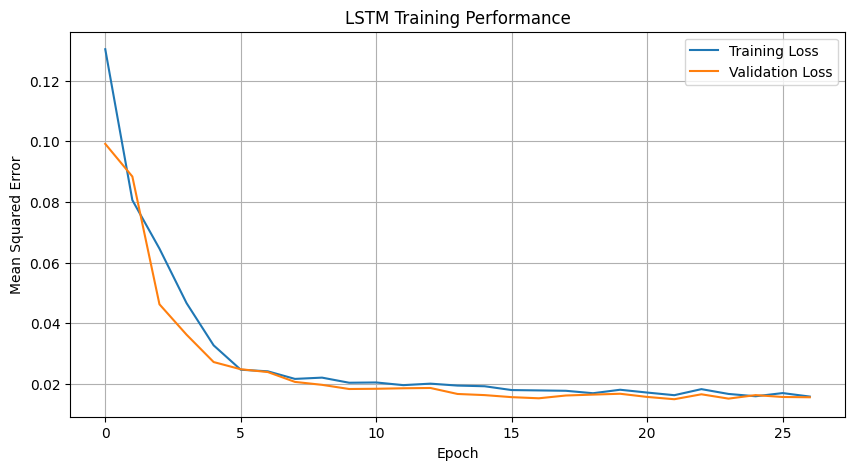

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training Performance")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_scaled = model.predict(X_test)

predicted = scaler.inverse_transform(
    pred_scaled
).flatten()

actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
r2 = r2_score(actual, predicted)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
MAE: 625.62
RMSE: 920.78
R2 Score: 0.7848


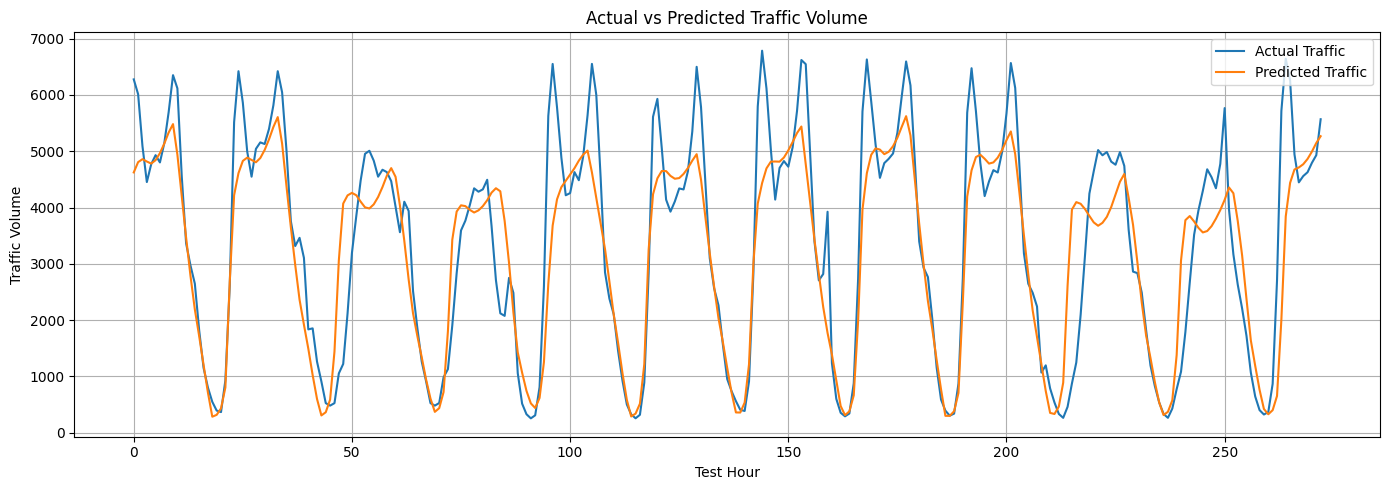

In [22]:
plt.figure(figsize=(14, 5))

plt.plot(actual, label="Actual Traffic")
plt.plot(predicted, label="Predicted Traffic")

plt.title("Actual vs Predicted Traffic Volume")
plt.xlabel("Test Hour")
plt.ylabel("Traffic Volume")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:
last_24 = all_scaled[-24:].reshape(1, 24, 1)

next_scaled = model.predict(last_24, verbose=0)

next_traffic = scaler.inverse_transform(
    next_scaled
)[0, 0]

print("Predicted traffic volume for the next hour:",
      round(max(0, next_traffic)))

Predicted traffic volume for the next hour: 5208


In [24]:
model.save("traffic_forecasting_lstm.keras")

print("Model saved successfully!")

Model saved successfully!


In [25]:
from google.colab import files
files.download("traffic_forecasting_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
import numpy as np

# Enter traffic volume for the previous 24 hours
user_input = input(
    "Enter 24 hourly traffic volumes separated by commas:\n"
)

# Convert input into numbers
values = [float(x.strip()) for x in user_input.split(",")]

if len(values) != 24:
    print("Error: Please enter exactly 24 values.")
else:
    # Prepare input for LSTM
    input_array = np.array(values).reshape(-1, 1)
    input_scaled = scaler.transform(input_array)
    input_scaled = input_scaled.reshape(1, 24, 1)

    # Predict next hour
    prediction_scaled = model.predict(input_scaled, verbose=0)
    prediction = scaler.inverse_transform(
        prediction_scaled
    )[0, 0]

    print("Predicted traffic volume for the next hour:",
          round(max(0, prediction)))

Enter 24 hourly traffic volumes separated by commas:
100,120,150,180,200,250,300,350,400,450,500,550,600,650,700,750,800,850,900,850,800,700,600,500
Predicted traffic volume for the next hour: 728
